In [1]:
### Import the liberaries 
import numpy as np
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt 

In [2]:
### Read the data 
data = sns.load_dataset("taxis")
data.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


### EDA

In [6]:
data.size

90062

In [8]:
data.shape

(6433, 14)

In [10]:
data.columns

Index(['pickup', 'dropoff', 'passengers', 'distance', 'fare', 'tip', 'tolls',
       'total', 'color', 'payment', 'pickup_zone', 'dropoff_zone',
       'pickup_borough', 'dropoff_borough'],
      dtype='object')

In [12]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[ns]
 1   dropoff          6433 non-null   datetime64[ns]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   object        
 9   payment          6389 non-null   object        
 10  pickup_zone      6407 non-null   object        
 11  dropoff_zone     6388 non-null   object        
 12  pickup_borough   6407 non-null   object        
 13  dropoff_borough  6388 non-null   object        
dtypes: datetime64[ns](2), float64(5), int64(

In [14]:
data.describe(include=[int,float])

,passengers,distance,fare,tip,tolls,total
count,6433.000000,6433.000000,6433.000000,6433.00000,6433.000000,6433.000000
mean,1.539251,3.024617,13.091073,1.97922,0.325273,18.517794
std,1.203768,3.827867,11.551804,2.44856,1.415267,13.815570
min,0.000000,0.000000,1.000000,0.00000,0.000000,1.300000
25%,1.000000,0.980000,6.500000,0.00000,0.000000,10.800000
50%,1.000000,1.640000,9.500000,1.70000,0.000000,14.160000
75%,2.000000,3.210000,15.000000,2.80000,0.000000,20.300000
max,6.000000,36.700000,150.000000,33.20000,24.020000,174.820000


In [16]:
data.describe(include=object)

,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
count,6433,6389,6407,6388,6407,6388
unique,2,2,194,203,4,5
top,yellow,credit card,Midtown Center,Upper East Side North,Manhattan,Manhattan
freq,5451,4577,230,245,5268,5206


### Data Visualizations 

### 1. Pairplot - Scatter plot( matrix) + histongram (diagonal)
- sns.pairplot(data)

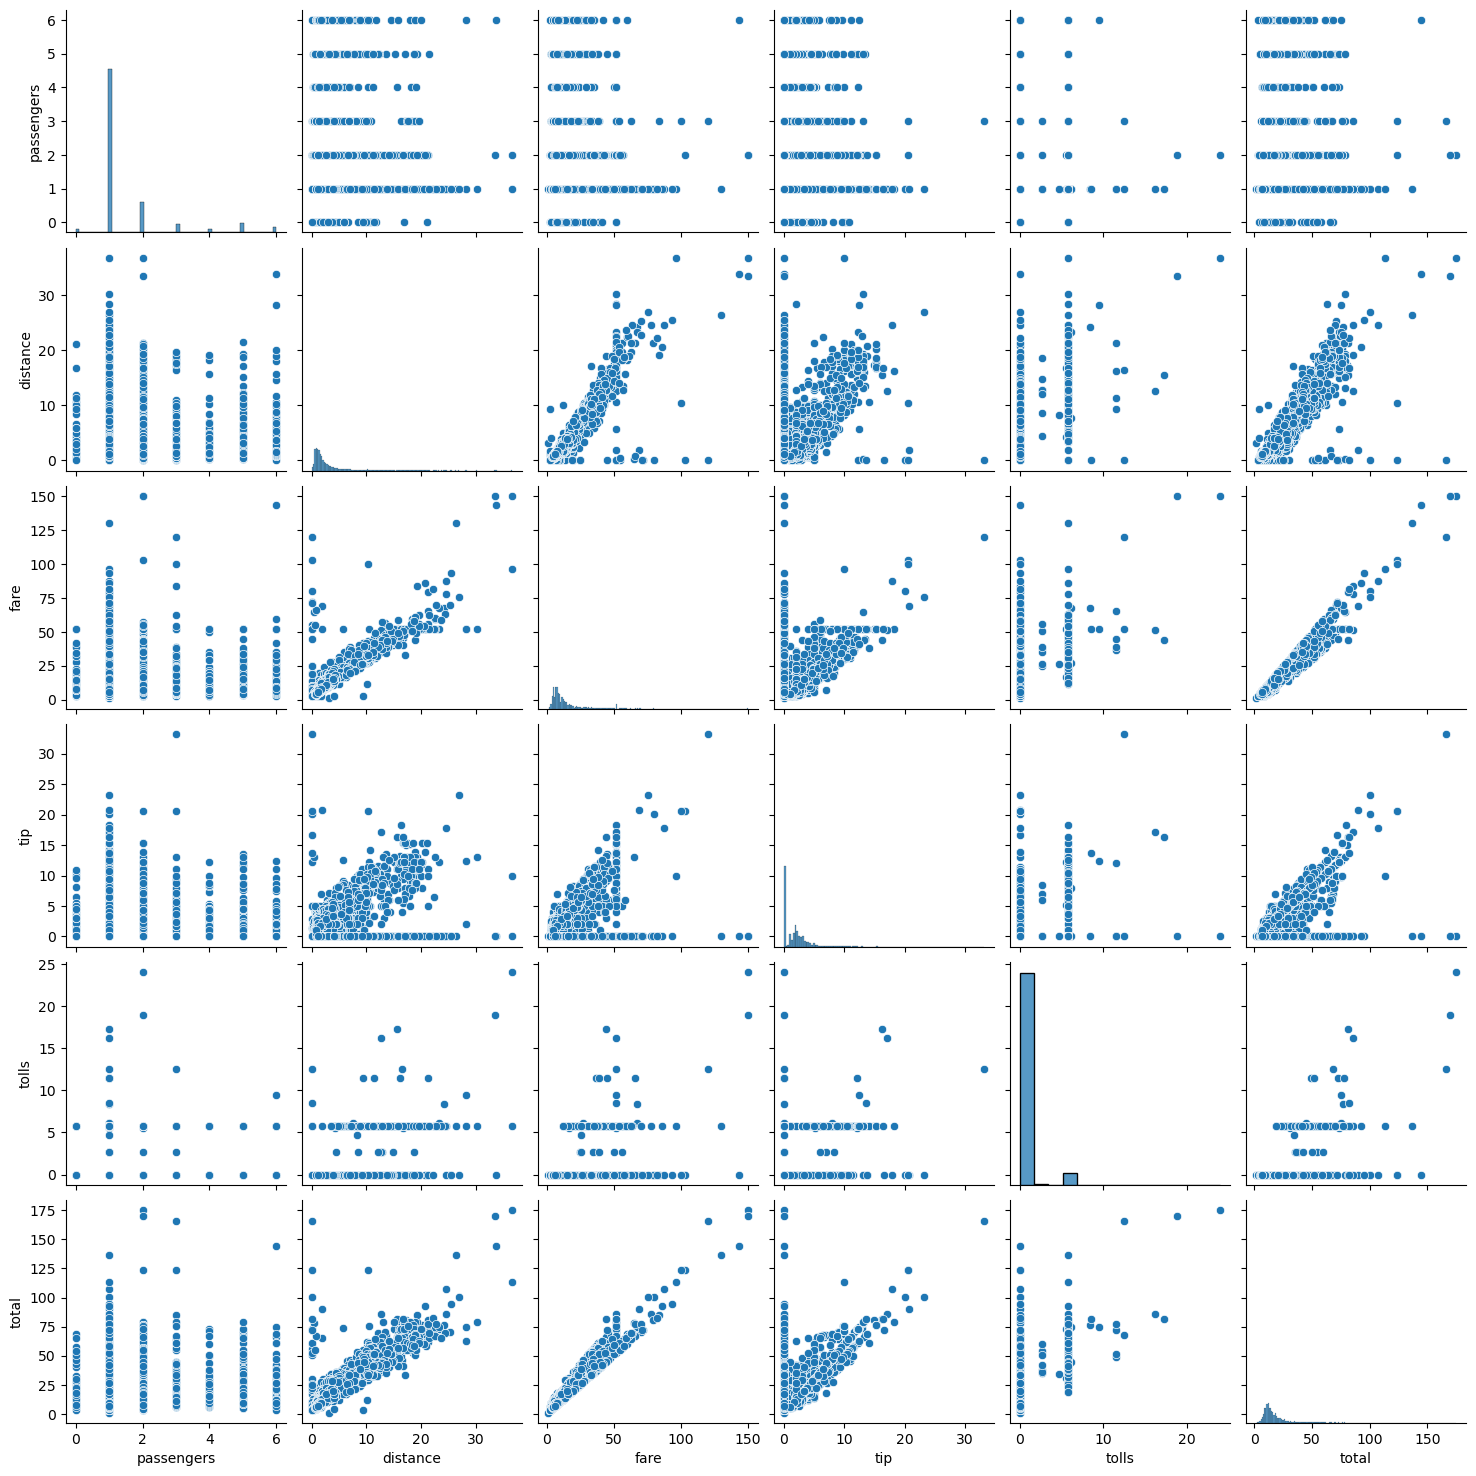

In [20]:
sns.pairplot(data)
plt.show()

#### 2. Heatmap - Used to visualize the correlation matrix (pearson correl matrix) 
- sns.heatmap( correlation_matrix ) 

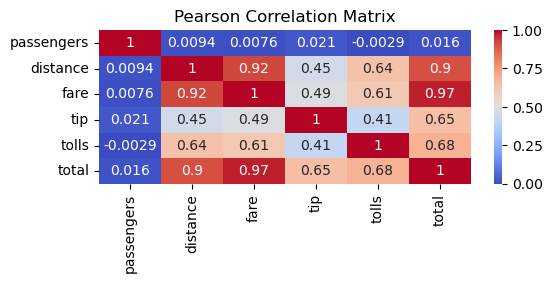

In [22]:
corr = data.corr(numeric_only=True)
plt.figure(figsize=(6,2))
sns.heatmap(corr,annot=True,cmap='coolwarm')
plt.title("Pearson Correlation Matrix")
plt.show()

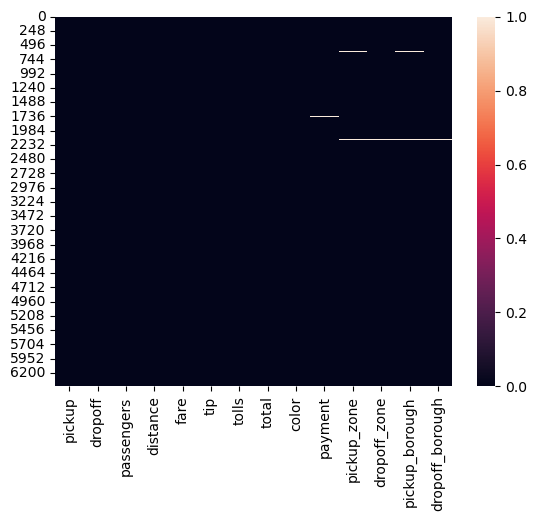

In [23]:
sns.heatmap(data.isnull())
plt.show()

#### 3.Histogram - Distribution of Numerical Columns ( single number column ) 
sns.histplot( column , bins ) 

In [25]:
## distance , tip , tolls and total 

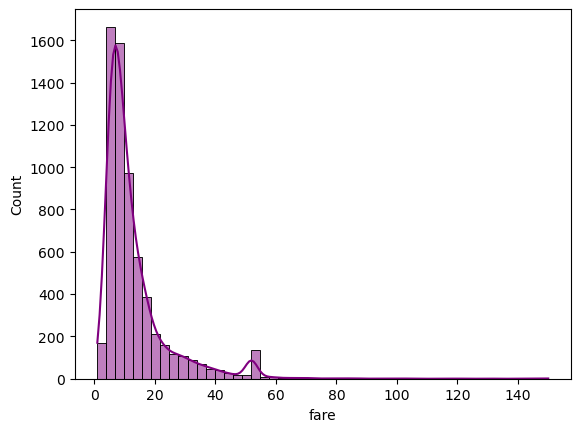

In [26]:
### 1.fare 
sns.histplot(data['fare'], bins = 50,color='purple',kde=True)
plt.show()

#### 4. KDE plot - distribution using kernel density estimator 
sns.kdeplot( column )

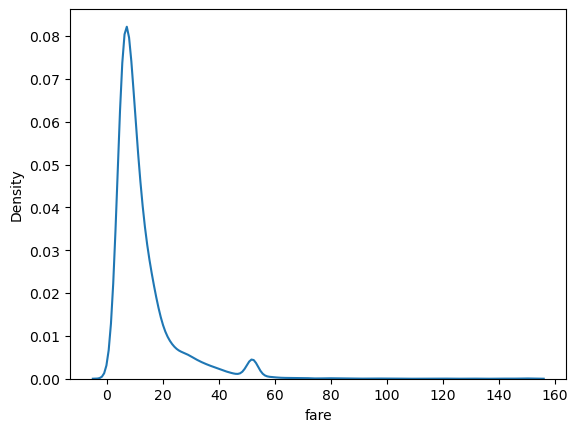

In [28]:
sns.kdeplot(data=data,x= 'fare')
plt.show()

### 5. Countplot - count of categorical variables 
sns.countplot( column ) 

In [30]:
## Payment , color , dropoff_borough , passengers 

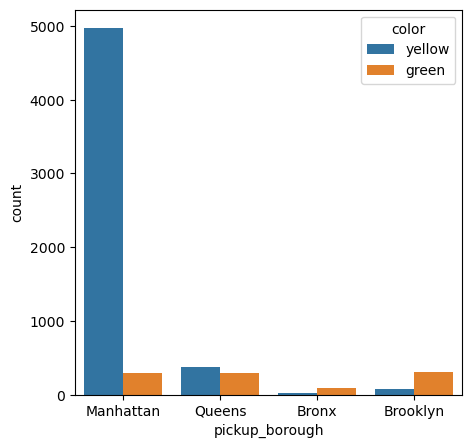

In [31]:
plt.figure(figsize=(5,5))
sns.countplot(data=data , x = 'pickup_borough',hue='color')
plt.show()

#### 6. Bar plot - bivaraite graph 
- numeric(y) and categorical data (x) 
- sns.barplot()

In [33]:
### 1. pickup_brough wise fare - avg and total 
### 2. pickup_borough wise tip - avg and total
### 3. pickup_borough wise toll - avg and total 

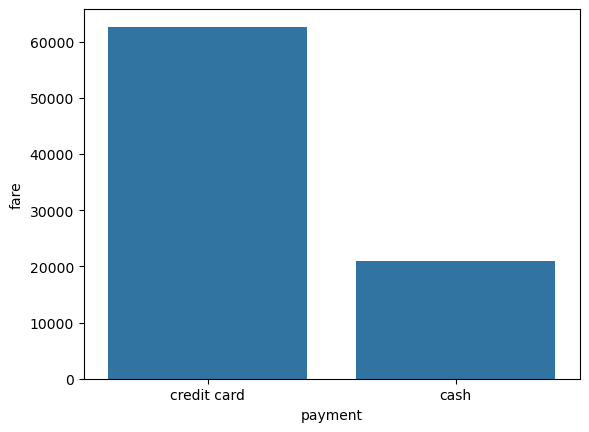

In [34]:
sns.barplot(data=data , x= 'payment',y='fare',errorbar=('ci',False),estimator='sum')
plt.show()

#### 7. pie chart - distribution graph 

In [36]:
pick = data.groupby('pickup_borough')['fare'].mean()
pick

pickup_borough
Bronx        20.999091
Brooklyn     16.520836
Manhattan    11.152889
Queens       24.934642
Name: fare, dtype: float64

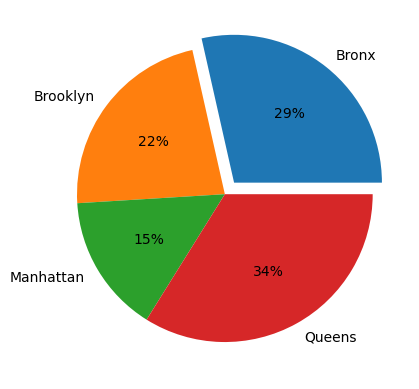

In [37]:
plt.pie(x=pick.values,labels=pick.index,data=pick,autopct="%0.0f%%",explode=[0.1,0,0,0])
plt.show()